# Experiment 8 - Part 1: Speech Recognition with Whisper

**Course:** HAAI302COM - Artificial Intelligence Laboratory

A voice assistant is a chain of three models: **speech to text** (ASR), a **language model** that decides what to say, and **text to speech** (TTS). If the first link mishears, everything after it answers the wrong question. So we start with the ear.

In this notebook we run OpenAI's **Whisper** locally, look at what it receives and returns, measure its accuracy with **word error rate (WER)** on 50 real recordings, and test the things that break it: small models, noise, rare vocabulary and silence.

We use `faster-whisper`, a fast re-implementation of Whisper that runs well on a CPU. The weights are the same OpenAI Whisper weights.

## 0. Setup

`voice_utils.py` holds the shared helpers (audio loading, `transcribe`, `wer`). The test set is `data/asr_set.json`: 50 clips from the **LibriSpeech** test sets (audiobook readings). 30 come from the `clean` set and 20 from the harder `other` set (more varied speakers and recording quality). Each clip has the correct transcript written by humans.

In [1]:
import json, time, os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, jiwer
from faster_whisper import WhisperModel
import voice_utils as vu

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 170)
asr = pd.DataFrame(json.load(open("data/asr_set.json")))
print(asr.groupby("subset").agg(clips=("file", "count"), total_seconds=("seconds", "sum"), mean_seconds=("seconds", "mean")).round(1))

        clips  total_seconds  mean_seconds
subset                                    
clean      30          218.2           7.3
other      20          115.8           5.8


## 1. What the model receives: a waveform and a spectrogram

A recording is a long list of numbers: air pressure sampled many times per second. Whisper wants **16,000 samples per second, one channel**. `load_audio` converts any file to that. Whisper then turns the waveform into a **log-mel spectrogram**: an 80-row picture where the horizontal axis is time and the vertical axis is pitch. This picture is the actual input to the neural network, so we look at it.

In [2]:
row = asr.iloc[0]
audio = vu.load_audio(row.file)
print("samples:", audio.shape[0], "| rate:", vu.SR, "Hz | duration:", round(len(audio) / vu.SR, 2), "s | range:", audio.min().round(2), "to", audio.max().round(2))
print("reference:", row.text)

samples: 56080 | rate: 16000 Hz | duration: 3.5 s | range: -0.29 to 0.22
reference: concord returned to its place amidst the tents


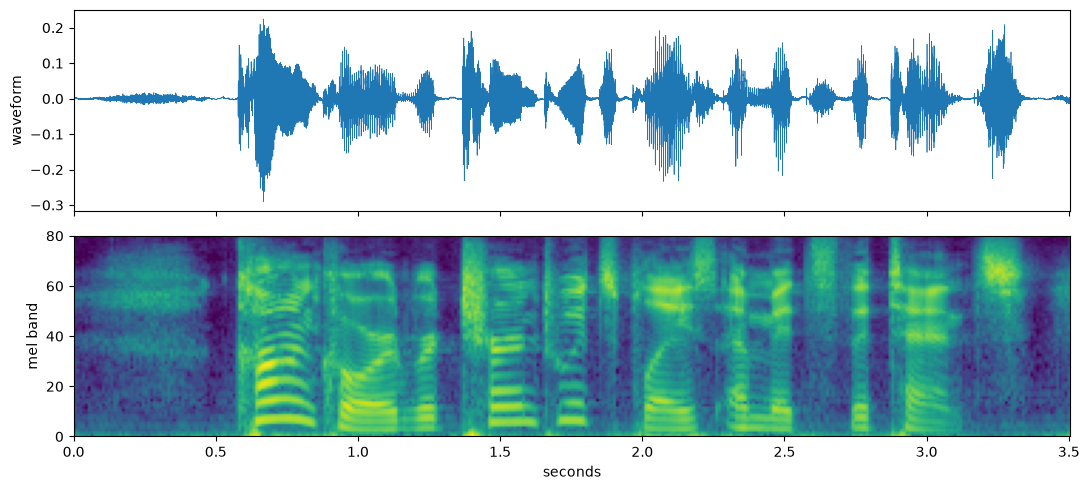

spectrogram shape (mel bands, frames): (80, 351)


In [3]:
# Whisper's own settings: 25 ms windows (n_fft=400), a new frame every 10 ms (hop_length=160), 80 mel bands
mel = librosa.feature.melspectrogram(y=audio, sr=vu.SR, n_fft=400, hop_length=160, n_mels=80)
logmel = librosa.power_to_db(mel, ref=np.max)
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(np.arange(len(audio)) / vu.SR, audio, lw=.5); ax[0].set_ylabel("waveform")
ax[1].imshow(logmel, origin="lower", aspect="auto", extent=[0, len(audio) / vu.SR, 0, 80]); ax[1].set_ylabel("mel band"); ax[1].set_xlabel("seconds")
plt.tight_layout(); plt.show()
print("spectrogram shape (mel bands, frames):", logmel.shape)

**What to notice:** a 3.5 second clip is 56,080 numbers, and the spectrogram turns it into a grid of 80 frequency bands by 351 time frames, 100 frames per second. Speech appears as bright bands that move with each syllable, and the pauses between words are dark. The network never sees raw samples: it sees this picture, which is why ASR models borrow ideas from image models.

## 2. The first transcription

`WhisperModel("tiny", device="cpu", compute_type="int8")` loads the smallest Whisper (39 million parameters). `compute_type="int8"` stores weights as 8-bit integers, which makes CPU inference faster with almost no accuracy loss. `model.transcribe` returns a lazy list of **segments** plus an `info` object. Each segment carries two confidence signals: `avg_logprob` (how sure the model was of its words; closer to 0 is better) and `no_speech_prob` (the chance that this part is not speech).

In [4]:
tiny = WhisperModel("tiny", device="cpu", compute_type="int8", cpu_threads=8)
text, segs, info, sec = vu.transcribe(tiny, audio, beam_size=5)
print("language:", info.language, round(info.language_probability, 3), "| time:", round(sec, 2), "s")
print("reference :", row.text)
print("whisper   :", text)

language: en 0.993 | time: 1.32 s
reference : concord returned to its place amidst the tents
whisper   : Concord returned to its place amidst the tents.


In [5]:
pd.DataFrame([dict(start=s.start, end=s.end, text=s.text, avg_logprob=s.avg_logprob, no_speech_prob=s.no_speech_prob) for s in segs]).round(3)

,start,end,text,avg_logprob,no_speech_prob
0,0.0,3.36,Concord returned to its place amidst the tents.,-0.462,0.008


**What to notice:** the transcript is right, with capital letters and a full stop added. Whisper also detected the language by itself (English, probability 0.993), and the segment confidence is high: avg_logprob of -0.46 and no_speech_prob of 0.008. Transcribing 3.5 seconds of audio took about 1.3 seconds on this CPU with the smallest model.

## 3. Word-level timestamps

With `word_timestamps=True` Whisper also returns when each word starts and ends and how confident it is in it. This is how subtitles and "click a word to jump to it" features work. Low-probability words are the ones to double-check.

In [6]:
_, segs, _, _ = vu.transcribe(tiny, audio, beam_size=5, word_timestamps=True)
pd.DataFrame([dict(word=w.word, start=w.start, end=w.end, prob=w.probability) for s in segs for w in s.words]).round(2)

,word,start,end,prob
0,Concord,0.64,1.20,0.56
1,returned,1.20,1.62,0.34
2,to,1.62,1.84,0.98
3,its,1.84,2.00,1.00
4,place,2.00,2.28,1.00
5,amidst,2.28,2.88,0.99
6,the,2.88,2.96,0.99
7,tents.,2.96,3.30,0.81


**What to notice:** every word is correct, yet the confidence differs a lot: function words such as 'its' and 'place' are near 1.0, but 'returned' is only 0.34 and 'Concord' 0.56. Rarer or less predictable words get lower probability. Confidence is not correctness, but low-probability words are where mistakes hide, so they are the ones to flag for review.

## 4. Word error rate, the standard ASR score

**WER** counts how many word-level edits turn the system output into the reference: substitutions (S), deletions (D) and insertions (I), divided by the number of words in the reference (N).

<p style="text-align:center">WER = (S + D + I) / N</p>

`jiwer` computes it. First, a toy example where we can count by hand, then the same example with and without text normalisation. A transcript with different capital letters or commas is not wrong speech recognition, so we lowercase and remove punctuation before comparing.

In [7]:
ref = "the quick brown fox jumps over the lazy dog"
hyp = "the quick brown box jumps over lazy dog today"        # fox->box (S), 'the' dropped (D), 'today' added (I)
m = jiwer.process_words(ref, hyp)
print(f"S={m.substitutions} D={m.deletions} I={m.insertions} correct={m.hits} N={len(ref.split())}  WER={m.wer:.3f}")

S=1 D=1 I=1 correct=7 N=9  WER=0.333


In [8]:
raw_ref, raw_hyp = "Hello, World. It's 5 o'clock!", "hello world it's five o'clock"
print("raw WER       :", round(jiwer.wer(raw_ref, raw_hyp), 3))
print("normalised WER:", round(vu.wer([raw_ref], [raw_hyp]), 3))
print("normalised ref:", vu.norm_text(raw_ref), "|", vu.norm_text(raw_hyp))

raw WER       : 1.0
normalised WER: 0.2
normalised ref: hello world its 5 oclock | hello world its five oclock


**What to notice:** in the toy example the output has one substitution (fox to box), one deletion ('the') and one insertion ('today') against 9 reference words, so WER is 3/9 = 0.33. Normalisation matters: the raw comparison gives WER 1.0 because of capital letters and punctuation, but after normalising only one error remains, '5' against 'five', giving 0.2. Digits against words is a formatting difference we have not fixed, and it will come back in section 6.

## 5. Experiment: model size versus accuracy and speed

Whisper comes in sizes: tiny (39M parameters), base (74M), small (244M), up to large (1.5B). Bigger models hear better and run slower. We transcribe all 50 clips with each of the three smaller sizes and record WER and the **real-time factor (RTF)**: seconds of compute per second of audio. RTF below 1 means faster than real time, which is what a live assistant needs.

Transcripts are saved to `asr_cache.json` so a re-run is instant. The first run takes a few minutes while the models download and run.

In [9]:
CACHE = "asr_cache.json"
cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
models = {}

def get_model(name):
    if name not in models:
        models[name] = WhisperModel(name, device="cpu", compute_type="int8", cpu_threads=8)
    return models[name]

def run_asr(name, frame, tag="", transform=None, **kw):
    # transcribe every clip in frame; results are cached per (model, settings, clip)
    out = []
    for _, r in frame.iterrows():
        key = f"{name}|{kw}|{tag}|{r.file}"
        if key not in cache:
            a = vu.load_audio(r.file)
            if transform:
                a = transform(a)
            text, _, _, sec = vu.transcribe(get_model(name), a, **kw)
            cache[key] = dict(text=text, sec=sec)
            json.dump(cache, open(CACHE, "w"))
        out.append(cache[key])
    return [o["text"] for o in out], sum(o["sec"] for o in out)

rows = []
for name in ["tiny", "base", "small"]:
    hyps, sec = run_asr(name, asr, beam_size=5)
    asr[f"hyp_{name}"] = hyps
    rows.append(dict(model=name, **{f"WER_{s}": vu.wer(asr[asr.subset == s].text, asr[asr.subset == s][f"hyp_{name}"]) for s in ["clean", "other"]},
                     WER_all=vu.wer(asr.text, asr[f"hyp_{name}"]), RTF=sec / asr.seconds.sum()))
pd.DataFrame(rows).set_index("model").round(3)

,WER_clean,WER_other,WER_all,RTF
model,,,,
tiny,0.082,0.113,0.094,0.198
base,0.049,0.081,0.062,0.376
small,0.039,0.073,0.052,1.032


**What to notice:** on 50 clips WER is 9.4 percent for tiny, 6.2 percent for base and 5.2 percent for small. The harder 'other' set is worse for all models (tiny 11.3 against 8.2 on clean). Speed goes the other way: the real-time factor is 0.20 for tiny, 0.38 for base and 1.03 for small, so on this CPU small is about as slow as real time and is too slow for a live assistant, while tiny is five times faster than real time. A GPU would change this; on a CPU, base is a sensible middle choice.

## 6. What kinds of mistakes? Looking at the errors

A single WER hides what went wrong. `process_words` splits the errors into substitutions, deletions and insertions. Then we print the three worst clips of the tiny model, with the reference and what it heard, to see whether the mistakes are real mishearings or only spelling differences.

In [10]:
rows = []
for name in ["tiny", "base", "small"]:
    m = jiwer.process_words([vu.norm_text(t) for t in asr.text], [vu.norm_text(h) or "<empty>" for h in asr[f"hyp_{name}"]])
    rows.append(dict(model=name, substitutions=m.substitutions, deletions=m.deletions, insertions=m.insertions, ref_words=m.hits + m.substitutions + m.deletions))
pd.DataFrame(rows).set_index("model")

,substitutions,deletions,insertions,ref_words
model,,,,
tiny,73,2,14,942
base,48,4,6,942
small,39,5,5,942


In [11]:
asr["wer_tiny"] = [jiwer.wer(vu.norm_text(r), vu.norm_text(h) or "<empty>") for r, h in zip(asr.text, asr.hyp_tiny)]
for _, r in asr.sort_values("wer_tiny", ascending=False).head(3).iterrows():
    print(f"[{r.subset}] WER {r.wer_tiny:.2f}\n  ref : {r.text}\n  tiny: {r.hyp_tiny}\n  small: {r.hyp_small}\n")

[other] WER 0.35
  ref : beg pardon sir but can you as a gentleman assure me that he is not here certainly said sir risdon
  tiny: Big part of the sir, but can you as a gentleman assure me that he is not here? Certainly, sir, Mr. Wisdom.
  small: Big part of sir, but can you as a gentleman assure me that he is not here certainly says your wisdom

[clean] WER 0.33
  ref : tuesday august eighteenth
  tiny: Tuesday, August 18th.
  small: Tuesday, August 18th.

[clean] WER 0.33
  ref : sunday august sixteenth
  tiny: Sunday, August 16th
  small: Sunday August 16th



**What to notice:** most errors are substitutions (tiny 73, small 39 out of 942 reference words), with few deletions, so the model mishears rather than skipping words. The three worst clips are instructive. Two are dates where the model heard everything right but wrote 'August 18th' while the reference says 'august eighteenth': a formatting difference that scores WER 0.33. The third is a real mishearing on the harder set: 'beg pardon sir' became 'Big part of the sir' and the rare name 'Risdon' became 'Wisdom'. WER therefore overstates the true error for number formats; production evaluations use a stronger normaliser that spells out numbers.

## 7. Experiment: beam search width

Whisper writes its transcript one token at a time. With `beam_size=1` it takes the single most likely token at every step (greedy decoding). With `beam_size=5` it keeps five candidate sentences alive and picks the best overall, which can rescue a sentence where the best first word leads to a bad ending. It is slower. We compare both on the `base` model.

In [12]:
rows = []
for beam in [1, 5]:
    hyps, sec = run_asr("base", asr, beam_size=beam)
    rows.append(dict(beam_size=beam, WER=vu.wer(asr.text, hyps), RTF=sec / asr.seconds.sum()))
pd.DataFrame(rows).set_index("beam_size").round(4)

,WER,RTF
beam_size,,
1,0.0637,0.3371
5,0.0616,0.3761


**What to notice:** beam search 5 gives WER 0.0616 against 0.0637 for greedy decoding, a difference of about 2 words in 942, while taking about 12 percent more time (RTF 0.376 against 0.337). On clean audiobook speech the gain is tiny. Beam search matters more on noisy or unusual audio, and for a live assistant, greedy is a reasonable default.

## 8. Experiment: noise

Real users speak in cars, kitchens and classrooms. We take 15 clean clips and mix in white noise at a chosen **signal-to-noise ratio (SNR)** in decibels: 20 dB is a quiet room, 10 dB a busy office, 0 dB means the noise is as loud as the speech. We keep the same noise pattern for every model so the comparison is fair.

In [13]:
sub = asr[asr.subset == "clean"].head(15)
rows = []
for snr in [None, 20, 10, 5, 0]:
    row = dict(snr_db="clean" if snr is None else snr)
    for name in ["tiny", "small"]:
        tf = None if snr is None else (lambda a, s=snr: vu.add_noise(a, s))
        hyps, _ = run_asr(name, sub, tag=f"snr{snr}", transform=tf, beam_size=5)
        row[f"WER_{name}"] = vu.wer(sub.text, hyps)
    rows.append(row)
noise = pd.DataFrame(rows).set_index("snr_db").round(3)
noise

,WER_tiny,WER_small
snr_db,,
clean,0.065,0.033
20,0.062,0.036
10,0.098,0.044
5,0.195,0.047
0,0.405,0.163


**What to notice:** the small model is much more robust than tiny. Tiny starts to degrade at 10 dB (WER 0.065 to 0.098), reaches 0.195 at 5 dB and 0.405 at 0 dB, where it gets 4 of 10 words wrong. Small holds near 0.04 down to 5 dB and only breaks at 0 dB (0.163). So extra capacity buys noise robustness, which is where small models lose most. The table uses one noise draw on 15 clips and white noise; real background noise (a fan, crowd chatter) is harder, so treat the numbers as a trend.

In [14]:
# listen to the same clip at 20 dB and 0 dB (play the cells in a notebook; in a script this just creates the objects)
from IPython.display import Audio, display
a0 = vu.load_audio(sub.iloc[0].file)
display(Audio(vu.add_noise(a0, 20), rate=vu.SR)); display(Audio(vu.add_noise(a0, 0), rate=vu.SR))

## 9. Experiment: rare words and the `initial_prompt`

Whisper has seen mostly everyday speech, so names such as "Qdrant" or "LangChain" are unusual for it. The `initial_prompt` argument feeds a short text before the audio, as if it had just been said, so the model is primed with the right spellings. We make 8 technical sentences spoken by Google's text-to-speech with an Indian-English accent (a different voice from LibriSpeech), transcribe them with the `base` model with and without a vocabulary prompt, and compare WER.

In [15]:
TECH = ["We store the embeddings in Qdrant and retrieve them with LangChain",
        "The student fine tuned Mistral with LoRA on Google Colab",
        "Pinecone and FAISS are popular vector databases",
        "Whisper converts speech to text and ElevenLabs converts text to speech",
        "PCCOER offers an honours programme in agentic AI",
        "LangGraph supports human in the loop checkpoints",
        "The FastAPI service streams tokens from the Gemini model",
        "Use the tokenizer from HuggingFace and tiktoken for counting"]
os.makedirs("data", exist_ok=True)
for i, s in enumerate(TECH):
    p = f"data/tech_{i}.mp3"
    if not os.path.exists(p):
        vu.tts_gtts(s, p)                       # accent: Indian English (tld="co.in")
tech = pd.DataFrame(dict(file=[f"data/tech_{i}.mp3" for i in range(8)], text=TECH, subset="tech"))
print(len(tech), "spoken sentences ready")

8 spoken sentences ready


In [16]:
PROMPT = "Technical talk about Qdrant, LangChain, LangGraph, LoRA, Mistral, Pinecone, FAISS, Whisper, ElevenLabs, PCCOER, FastAPI, HuggingFace, tiktoken."
plain, _ = run_asr("base", tech, tag="tech", beam_size=5)
primed, _ = run_asr("base", tech, tag="tech", beam_size=5, initial_prompt=PROMPT)
print("WER without prompt:", round(vu.wer(tech.text, plain), 3), "| with prompt:", round(vu.wer(tech.text, primed), 3))
pd.DataFrame(dict(reference=tech.text.str[:45], plain=plain, primed=primed))

WER without prompt: 0.292 | with prompt: 0.042


,reference,plain,primed
0,We store the embeddings in Qdrant and retriev,We store the embeddings in Cudrant and retrieve them with Lang Chain.,We store the embeddings in Qdrant and retrieve them with LangChain.
1,The student fine tuned Mistral with LoRA on G,The student fine tuned Mastral with Laura on Google Colab.,The student fine-tuned Mistral with LoRA on Google Collab.
2,Pinecone and FAISS are popular vector databas,Pine cone and F AISS are popular vector databases.,Pinecone and FAISS are popular vector databases.
3,Whisper converts speech to text and ElevenLab,Whisper converts speech to text and 11 labs converts text to speech.,Whisper converts speech to text and ElevenLabs converts text to speech.
4,PCCOER offers an honours programme in agentic,PCCOER offers an honours programme in Agentech AI.,PCCOER offers an honors program in Agentic AI.
5,LangGraph supports human in the loop checkpoi,Land graph supports human in the loop checkpoints.,LangGraph supports human in the loop checkpoints.
6,The FastAPI service streams tokens from the G,The fast API service stream tokens from the Gemini model.,The FastAPI service streams tokens from the Gemini model.
7,Use the tokenizer from HuggingFace and tiktok,Use the tokenizer from hugging face and tick token for counting.,Use the tokenizer from HuggingFace and Tiktoken for counting.


**What to notice:** a vocabulary prompt cuts WER from 0.29 to 0.04. Without it Whisper spelled what it heard: 'Cudrant', 'Mastral', 'Laura', 'Pine cone', '11 labs', 'Land graph', 'tick token'. With the prompt it copied the right spellings for nearly every term. Remaining difference: 'Collab' instead of 'Colab'. The prompt does not teach the model new sounds; it only tells it which spellings are likely. The danger is bias: if a prompted word is not actually spoken, the model may still write it.

## 10. Silence, music and voice-activity detection

What does Whisper write when nobody is speaking? A model trained to always produce text could invent some: published studies have found invented sentences in Whisper output on silent stretches. We test three non-speech signals: faint room noise, a short synthetic melody, and a speech clip surrounded by 12 seconds of silence on each side. `vad_filter=True` runs a small voice-activity detector first and removes the non-speech parts before Whisper sees them. We record the number of segments, the text and the time.

In [17]:
rng = np.random.default_rng(1)
noise_only = rng.normal(0, 0.003, 10 * vu.SR).astype("float32")
tt = np.arange(vu.SR // 2) / vu.SR
melody = np.concatenate([np.sin(2 * np.pi * f * tt) * np.hanning(len(tt)) * 0.3 for f in [262, 330, 392, 523, 392, 330, 262, 330] * 2]).astype("float32")
gap = np.zeros(12 * vu.SR, dtype="float32")
padded = np.concatenate([gap, audio, gap])
rows = []
for label, x in [("faint noise, 10 s", noise_only), ("melody, 8 s", melody), ("speech + 24 s silence", padded)]:
    for vad in [False, True]:
        text, segs, _, sec = vu.transcribe(tiny, x, beam_size=5, vad_filter=vad)
        rows.append(dict(signal=label, vad_filter=vad, segments=len(segs), text=text[:50], seconds=round(sec, 2)))
pd.DataFrame(rows)

,signal,vad_filter,segments,text,seconds
0,"faint noise, 10 s",False,0,,3.84
1,"faint noise, 10 s",True,0,,0.63
2,"melody, 8 s",False,0,,1.11
3,"melody, 8 s",True,0,,0.54
4,speech + 24 s silence,False,1,Concord return to its place amidst the tents.,1.34
5,speech + 24 s silence,True,1,Concord return to its place amidst the tents.,1.44


**What to notice:** none of the three non-speech signals produced invented text, with or without the filter. Published studies have found that Whisper sometimes invents sentences on silent stretches, and we could not reproduce that with this version, probably because Whisper checks its own confidence (no_speech_prob and log-probability thresholds) and drops doubtful segments. The VAD filter still saves time: the melody takes 0.54 s with it against 1.11 s without, because Whisper never runs on the non-speech parts. (The first row also pays start-up costs for that call.) For the speech clip padded with silence there is no saving: the 24 s padding fits in one 30 second window either way. Check your own audio for odd output before trusting this in production.

## 11. Recap and exercises

- Whisper takes 16 kHz audio, makes a log-mel spectrogram and writes tokens; segments carry confidence values.
- WER = (S + D + I) / N; always normalise text before comparing.
- Model size trades accuracy for speed; noise hurts small models first; beam search and vocabulary prompts help at some cost.
- Voice-activity detection and Whisper's own confidence checks keep silence from becoming text; keep an eye on empty or odd output in production.

**Try yourself:** (1) add the `medium` model (about 1.5 GB) and see how much WER falls on the `other` set; (2) record yourself and transcribe the file; (3) compare `compute_type="float32"` with `int8` on 10 clips.

Next: **Notebook 02** connects the transcript to a language model and speaks the answer.